# Language Identification with FastText Wiki Vectors

Models compared using **Macro-F1** (written from scratch, no sklearn):
1. Logistic Regression (0 hidden layers)
2. MLP (1 hidden layer)
3. MLP (2 hidden layers)
4. LSTM
5. GRU
6. FastText supervised classifier

Data: IndicCorpV2, 23 languages, 1000 sentences each (800 train / 100 val / 100 test).

In [1]:
!pip -q install datasets fasttext

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.4/73.4 kB 2.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Imports and settings

In [2]:
import re, random, zlib
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import tensorflow as tf
import fasttext
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# language code -> IndicCorpV2 split name
LANGUAGES = {
    "as": "asm_Beng", "brx": "brx_Deva", "bn": "ben_Beng", "doi": "doi_Deva",
    "gom": "gom_Deva", "gu": "guj_Gujr", "hi": "hin_Deva", "kha": "khasi",
    "kn": "kan_Knda", "ks": "kas_Arab", "mai": "mai_Deva", "ml": "mal_Mlym",
    "mni": "mni_Mtei", "mr": "mar_Deva", "ne": "npi_Deva", "or": "ory_Orya",
    "pa": "pan_Guru", "sa": "san_Deva", "sat": "santhali", "sd": "snd_Deva",
    "ta": "tam_Taml", "te": "tel_Telu", "ur": "urd_Arab",
}
LABEL2ID = {code: i for i, code in enumerate(LANGUAGES)}
NUM_CLASSES = len(LANGUAGES)

DIM = 300               # FastText wiki vector size
MAX_SEQ_LEN = 40        # max words per sentence for LSTM/GRU
MAX_VECTOR_WORDS = 100_000   # how many words to read from each wiki .vec file
WIKI_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-wiki"

WORD_RE = re.compile(r"\w+")

## 2. Build the dataset

In [3]:
def clean(text):
    text = text.replace("\u200b", " ").replace("\u200c", "").replace("\u200d", "")
    return re.sub(r"\s+", " ", text).strip()

def split_sentences(paragraph):
    parts = re.split(r"(?<=[.!?।॥؟])\s+", clean(paragraph))
    return [p for p in parts if len(WORD_RE.findall(p)) >= 2]   # keep sentences with 2+ words

In [5]:
rows = []
for code, split_name in LANGUAGES.items():
    print("Collecting", code)
    stream = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=split_name, streaming=True)

    sentences, seen = [], set()
    for item in stream:
        for s in split_sentences(item["text"]):
            if s not in seen:            # remove duplicates
                seen.add(s)
                sentences.append(s)
        if len(sentences) >= 1000:
            break
    sentences = sentences[:1000]

    random.Random(SEED + LABEL2ID[code]).shuffle(sentences)
    for i, s in enumerate(sentences):
        split = "train" if i < 800 else ("val" if i < 900 else "test")
        rows.append((s, code, split))

df = pd.DataFrame(rows, columns=["text", "label", "split"])
print(df.groupby(["label", "split"]).size().unstack())

split  test  train  val
label                  
as      100    800  100
bn      100    800  100
brx     100    800  100
doi     100    800  100
gom     100    800  100
gu      100    800  100
hi      100    800  100
kha     100    800  100
kn      100    800  100
ks      100    800  100
mai     100    800  100
ml      100    800  100
mni     100    800  100
mr      100    800  100
ne      100    800  100
or      100    800  100
pa      100    800  100
sa      100    800  100
sat     100    800  100
sd      100    800  100
ta      100    800  100
te      100    800  100
ur      100    800  100


## 3. Macro-F1 from scratch

For each language: precision = TP/(TP+FP), recall = TP/(TP+FN), F1 = 2PR/(P+R).
Macro-F1 is the average of the 23 F1 values.

In [6]:
def macro_f1(y_true, y_pred):
    f1_scores = []
    for c in range(NUM_CLASSES):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        f1_scores.append(f1)
    return float(np.mean(f1_scores))

## 4. FastText wiki vectors -> sentence features

- Download the first 100,000 words of `wiki.<lang>.vec` for each language and keep only the words we need.
- If a word (or the whole language file) is missing, it gets a fixed random vector (same word always gives the same vector).
- **Average vector** (300 numbers per sentence) is used for Logistic Regression and MLP.
- **Sequence of vectors** (40 x 300 per sentence) is used for LSTM and GRU.

In [7]:
def load_wiki_vectors(code, needed_words):
    vectors = {}
    try:
        response = requests.get(f"{WIKI_URL}/wiki.{code}.vec", stream=True, timeout=120)
        response.raise_for_status()
        for i, line in enumerate(response.iter_lines()):
            if i == 0:
                continue                      # first line is the header
            if i > MAX_VECTOR_WORDS:
                break
            parts = line.decode("utf-8").split()
            if len(parts) == DIM + 1 and parts[0].lower() in needed_words:
                vectors[parts[0].lower()] = np.array(parts[1:], dtype=np.float32)
        response.close()
    except Exception as e:
        print(f"  wiki vectors not available for {code}: {e}")
    return vectors

def get_vector(word, vectors):
    if word in vectors:
        return vectors[word]
    rng = np.random.default_rng(zlib.crc32(word.encode()))
    return rng.normal(0, 0.1, DIM).astype(np.float32)

In [8]:
X_avg = np.zeros((len(df), DIM), dtype=np.float32)
X_seq = np.zeros((len(df), MAX_SEQ_LEN, DIM), dtype=np.float32)

for code in LANGUAGES:
    idx = df.index[df["label"] == code]
    tokens = {i: WORD_RE.findall(df.at[i, "text"].lower())[:MAX_SEQ_LEN] for i in idx}
    needed = {w for t in tokens.values() for w in t}

    vectors = load_wiki_vectors(code, needed)
    print(f"{code}: {len(vectors)} of {len(needed)} words found in wiki vectors")

    for i in idx:
        vecs = [get_vector(w, vectors) for w in tokens[i]]
        if vecs:
            X_seq[i, :len(vecs)] = vecs
            X_avg[i] = np.mean(vecs, axis=0)

as: 608 of 1695 words found in wiki vectors
  wiki vectors not available for brx: 403 Client Error: Forbidden for url: https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.brx.vec
brx: 0 of 1179 words found in wiki vectors
bn: 610 of 1408 words found in wiki vectors
  wiki vectors not available for doi: 403 Client Error: Forbidden for url: https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.doi.vec
doi: 0 of 953 words found in wiki vectors
gom: 478 of 1577 words found in wiki vectors
gu: 473 of 1635 words found in wiki vectors
hi: 594 of 1266 words found in wiki vectors
  wiki vectors not available for kha: 403 Client Error: Forbidden for url: https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.kha.vec
kha: 0 of 5830 words found in wiki vectors
kn: 261 of 1466 words found in wiki vectors
ks: 75 of 3670 words found in wiki vectors
mai: 359 of 1638 words found in wiki vectors
ml: 218 of 1569 words found in wiki vectors
  wiki vectors not available for mni: 403 Client Err

In [9]:
y = df["label"].map(LABEL2ID).values
is_train = (df["split"] == "train").values
is_val = (df["split"] == "val").values
is_test = (df["split"] == "test").values

def split_data(X):
    return X[is_train], X[is_val], X[is_test]

Xavg_train, Xavg_val, Xavg_test = split_data(X_avg)
Xseq_train, Xseq_val, Xseq_test = split_data(X_seq)
y_train, y_val, y_test = y[is_train], y[is_val], y[is_test]

del X_seq   # free memory
print(Xavg_train.shape, Xseq_train.shape)

(18400, 300) (18400, 40, 300)


## 5. Logistic Regression and MLP

Same input (300-d average vector), same softmax output layer.
Only the number of hidden layers changes: 0, 1 or 2.

In [10]:
results = {}

def train_and_test(model, X_train, X_val, X_test, name):
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=15, batch_size=64, verbose=2,
        callbacks=[tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)],
    )
    pred = model.predict(X_test, verbose=0).argmax(axis=1)
    results[name] = macro_f1(y_test, pred)
    print(f"{name}: Macro-F1 = {results[name]:.4f}")

def build_mlp(hidden_sizes):
    layers = [tf.keras.Input(shape=(DIM,))]
    for size in hidden_sizes:
        layers.append(tf.keras.layers.Dense(size, activation="relu"))
    layers.append(tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"))
    return tf.keras.Sequential(layers)

train_and_test(build_mlp([]), Xavg_train, Xavg_val, Xavg_test, "Logistic Regression")
train_and_test(build_mlp([128]), Xavg_train, Xavg_val, Xavg_test, "MLP (1 hidden)")
train_and_test(build_mlp([128, 64]), Xavg_train, Xavg_val, Xavg_test, "MLP (2 hidden)")

Epoch 1/15
288/288 - 1s - 5ms/step - accuracy: 0.8436 - loss: 1.4406 - val_accuracy: 0.9317 - val_loss: 0.7983
Epoch 2/15
288/288 - 1s - 2ms/step - accuracy: 0.9465 - loss: 0.6559 - val_accuracy: 0.9539 - val_loss: 0.5551
Epoch 3/15
288/288 - 1s - 2ms/step - accuracy: 0.9578 - loss: 0.4789 - val_accuracy: 0.9626 - val_loss: 0.4259
Epoch 4/15
288/288 - 1s - 3ms/step - accuracy: 0.9658 - loss: 0.3750 - val_accuracy: 0.9657 - val_loss: 0.3446
Epoch 5/15
288/288 - 1s - 3ms/step - accuracy: 0.9690 - loss: 0.3070 - val_accuracy: 0.9674 - val_loss: 0.2890
Epoch 6/15
288/288 - 1s - 4ms/step - accuracy: 0.9709 - loss: 0.2594 - val_accuracy: 0.9657 - val_loss: 0.2491
Epoch 7/15
288/288 - 1s - 5ms/step - accuracy: 0.9716 - loss: 0.2244 - val_accuracy: 0.9661 - val_loss: 0.2193
Epoch 8/15
288/288 - 1s - 5ms/step - accuracy: 0.9719 - loss: 0.1980 - val_accuracy: 0.9670 - val_loss: 0.1966
Epoch 9/15
288/288 - 2s - 8ms/step - accuracy: 0.9725 - loss: 0.1775 - val_accuracy: 0.9661 - val_loss: 0.1788
E

## 6. LSTM and GRU

Input is the sequence of word vectors (padded with zeros to 40 words).
`Masking` tells the layer to ignore the zero padding.

In [11]:
def build_rnn(rnn_layer):
    return tf.keras.Sequential([
        tf.keras.Input(shape=(MAX_SEQ_LEN, DIM)),
        tf.keras.layers.Masking(mask_value=0.0),
        rnn_layer(96),
        tf.keras.layers.Dropout(0.25),
        tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
    ])

train_and_test(build_rnn(tf.keras.layers.LSTM), Xseq_train, Xseq_val, Xseq_test, "LSTM")
train_and_test(build_rnn(tf.keras.layers.GRU), Xseq_train, Xseq_val, Xseq_test, "GRU")

Epoch 1/15
288/288 - 29s - 100ms/step - accuracy: 0.8622 - loss: 0.5776 - val_accuracy: 0.9217 - val_loss: 0.2336
Epoch 2/15
288/288 - 25s - 88ms/step - accuracy: 0.9430 - loss: 0.1876 - val_accuracy: 0.9278 - val_loss: 0.2576
Epoch 3/15
288/288 - 25s - 86ms/step - accuracy: 0.9574 - loss: 0.1579 - val_accuracy: 0.9652 - val_loss: 0.1221
Epoch 4/15
288/288 - 41s - 141ms/step - accuracy: 0.9744 - loss: 0.0943 - val_accuracy: 0.9722 - val_loss: 0.1096
Epoch 5/15
288/288 - 25s - 87ms/step - accuracy: 0.9779 - loss: 0.0819 - val_accuracy: 0.9748 - val_loss: 0.0951
Epoch 6/15
288/288 - 25s - 87ms/step - accuracy: 0.9816 - loss: 0.0669 - val_accuracy: 0.9752 - val_loss: 0.0873
Epoch 7/15
288/288 - 26s - 89ms/step - accuracy: 0.9820 - loss: 0.0633 - val_accuracy: 0.9774 - val_loss: 0.0781
Epoch 8/15
288/288 - 25s - 88ms/step - accuracy: 0.9858 - loss: 0.0503 - val_accuracy: 0.9804 - val_loss: 0.0732
Epoch 9/15
288/288 - 41s - 141ms/step - accuracy: 0.9874 - loss: 0.0448 - val_accuracy: 0.9800

## 7. FastText supervised classifier

FastText learns its own word and character n-gram embeddings directly from the labelled text.
File format: `__label__<language> sentence`.

In [12]:
for split in ["train", "test"]:
    with open(f"{split}.txt", "w", encoding="utf-8") as f:
        for text, label in df.loc[df["split"] == split, ["text", "label"]].values:
            f.write(f"__label__{label} {text}\n")

ft_model = fasttext.train_supervised(input="train.txt", lr=0.5, epoch=25, wordNgrams=2, minn=2, maxn=5, dim=100)

In [ ]:
# ft_model.predict() fails with NumPy 2, so we call the underlying function directly
def ft_predict(text):
    prob, label = ft_model.f.predict(text + "\n", 1, 0.0, "strict")[0]
    return LABEL2ID[label.replace("__label__", "")]

test_texts = df.loc[is_test, "text"].tolist()
ft_pred = np.array([ft_predict(t) for t in test_texts])

results["FastText Classifier"] = macro_f1(y_test, ft_pred)
print(f"FastText Classifier: Macro-F1 = {results['FastText Classifier']:.4f}")

## 8. Final comparison

              Model  Macro-F1
Logistic Regression  0.975616
     MLP (1 hidden)  0.985198
     MLP (2 hidden)  0.982999
               LSTM  0.985211
                GRU  0.985252
FastText Classifier  0.946677


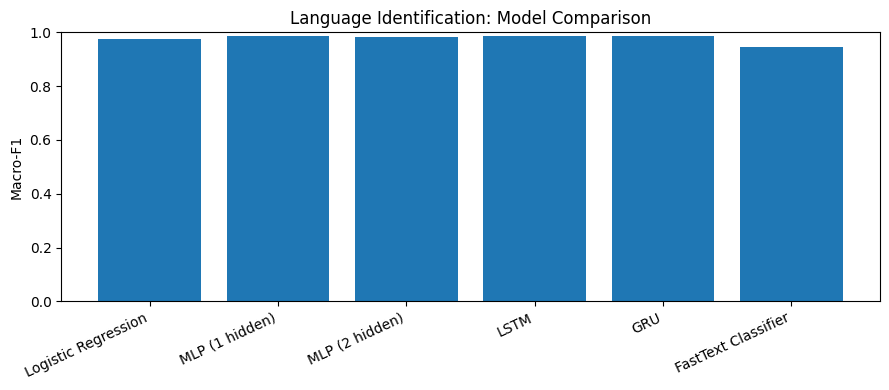

In [14]:
results_df = pd.DataFrame({"Model": list(results.keys()), "Macro-F1": list(results.values())})
print(results_df.to_string(index=False))

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["Macro-F1"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.title("Language Identification: Model Comparison")
plt.tight_layout()
plt.show()